In [1]:
''' Evaluate regression models using RMSE, MAE, and R-squared metrics to 
accurately measure prediction errors for 
continuous outcomes, such as predicting enrollment probability scores'''

' Evaluate regression models using RMSE, MAE, and R-squared metrics to \naccurately measure prediction errors for \ncontinuous outcomes, such as predicting enrollment probability scores'

In [2]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score

In [3]:
# loading dataset
df = pd.read_csv('Adm.csv')
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.96,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.80,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.67,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.78,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.63,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [4]:
# inspecting dataset shape and columns
print(df.shape)
print(df.columns.tolist())
print(df.dtypes)

(1000, 12)
['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit', 'Application_DateTime', 'University_Name', 'region']
Serial No.                int64
GRE Score                 int64
TOEFL Score               int64
University Rating         int64
SOP                     float64
LOR                     float64
CGPA                    float64
Research                  int64
Chance of Admit         float64
Application_DateTime     object
University_Name          object
region                   object
dtype: object


In [5]:
# checking dataset statistics and missing values
print(df.isnull().sum())
print(df.describe())

Serial No.              0
GRE Score               0
TOEFL Score             0
University Rating       0
SOP                     0
LOR                     0
CGPA                    0
Research                0
Chance of Admit         0
Application_DateTime    0
University_Name         0
region                  0
dtype: int64
        Serial No.    GRE Score  TOEFL Score  University Rating          SOP  \
count  1000.000000  1000.000000  1000.000000        1000.000000  1000.000000   
mean    500.500000   315.965000   106.564000           3.015000     3.393500   
std     288.819436    13.415653     7.634277           1.317768     1.027279   
min       1.000000   290.000000    92.000000           1.000000     0.900000   
25%     250.750000   305.000000   101.000000           2.000000     2.500000   
50%     500.500000   316.000000   107.000000           3.000000     3.500000   
75%     750.250000   326.250000   113.000000           4.000000     4.000000   
max    1000.000000   340.000000   1

In [6]:
# checking feature correlations with enrollment probability
corr_series = df.corr(numeric_only=True)['Chance of Admit'].sort_values(ascending=False)
print(corr_series)

Chance of Admit      1.000000
CGPA                 0.877636
GRE Score            0.502282
LOR                  0.487342
TOEFL Score          0.474981
Research             0.394458
University Rating    0.381242
SOP                  0.323175
Serial No.          -0.064735
Name: Chance of Admit, dtype: float64


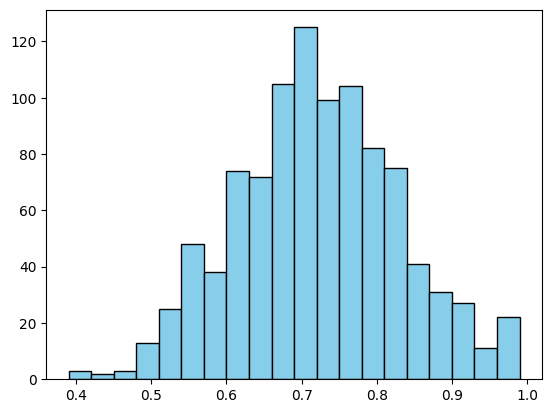

In [7]:
# plotting distribution of enrollment probability scores
plt.hist(df['Chance of Admit'], bins=20, color='skyblue', edgecolor='black')
plt.show()

In [8]:
# separating features and target variable
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[features]
y = df['Chance of Admit']
print(X.head())

   GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  Research
0        337          118                  4  4.5  4.5  9.65         1
1        324          107                  4  4.0  4.5  8.87         1
2        316          104                  3  3.0  3.5  8.00         1
3        322          110                  3  3.5  2.5  8.67         1
4        314          103                  2  2.0  3.0  8.21         0


In [9]:
# splitting data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(800, 7) (200, 7)


In [10]:
# scaling features using standard scaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
# initializing multiple regression models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.001),
    'Decision Tree': DecisionTreeRegressor(max_depth=6, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42)
}

In [12]:
# training regression models on training data
trained_models = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model

In [13]:
# predicting continuous outcomes on train and test sets
predictions = {}
for name, model in trained_models.items():
    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)
    predictions[name] = {'train': train_pred, 'test': test_pred}

In [14]:
# calculating rmse, mae and r2 metrics for train and test sets
eval_records = []
for name, preds in predictions.items():
    train_mae = mean_absolute_error(y_train, preds['train'])
    test_mae = mean_absolute_error(y_test, preds['test'])
    
    train_rmse = np.sqrt(mean_squared_error(y_train, preds['train']))
    test_rmse = np.sqrt(mean_squared_error(y_test, preds['test']))
    
    train_r2 = r2_score(y_train, preds['train'])
    test_r2 = r2_score(y_test, preds['test'])
    
    eval_records.append({
        'Model': name,
        'Train MAE': train_mae,
        'Test MAE': test_mae,
        'Train RMSE': train_rmse,
        'Test RMSE': test_rmse,
        'Train R2': train_r2,
        'Test R2': test_r2
    })

eval_df = pd.DataFrame(eval_records)
print(eval_df.to_string(index=False))

            Model  Train MAE  Test MAE  Train RMSE  Test RMSE  Train R2  Test R2
Linear Regression   0.019551  0.019577    0.024517   0.024644  0.950270 0.940680
 Ridge Regression   0.019551  0.019574    0.024517   0.024638  0.950270 0.940710
 Lasso Regression   0.019641  0.019638    0.024643   0.024772  0.949758 0.940062
    Decision Tree   0.022738  0.034073    0.029199   0.043309  0.929462 0.816797
    Random Forest   0.009297  0.023388    0.011747   0.030661  0.988583 0.908178


In [15]:
# displaying summary of test evaluation metrics
metrics_summary = eval_df[['Model', 'Test MAE', 'Test RMSE', 'Test R2']].copy()
metrics_summary = metrics_summary.sort_values(by='Test R2', ascending=False)
print(metrics_summary.to_string(index=False))

            Model  Test MAE  Test RMSE  Test R2
 Ridge Regression  0.019574   0.024638 0.940710
Linear Regression  0.019577   0.024644 0.940680
 Lasso Regression  0.019638   0.024772 0.940062
    Random Forest  0.023388   0.030661 0.908178
    Decision Tree  0.034073   0.043309 0.816797


In [16]:
# identifying best performing regression model
best_row = metrics_summary.iloc[0]
best_model_name = best_row['Model']
print('Best Model:', best_model_name)
print('Best Test R2 Score:', best_row['Test R2'])
print('Best Test RMSE:', best_row['Test RMSE'])
print('Best Test MAE:', best_row['Test MAE'])

Best Model: Ridge Regression
Best Test R2 Score: 0.9407097029705774
Best Test RMSE: 0.02463765534679036
Best Test MAE: 0.019574390527970813


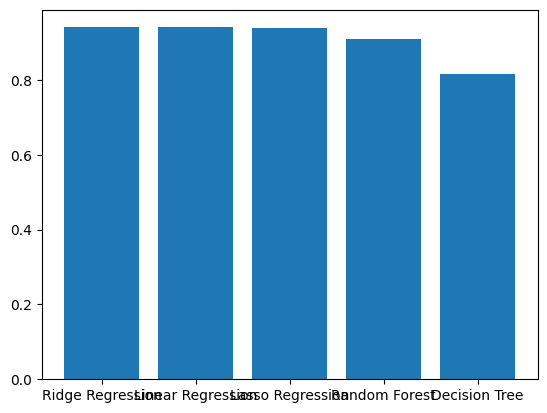

In [17]:
# plotting r2 score comparison across models
plt.bar(metrics_summary['Model'], metrics_summary['Test R2'])
plt.show()

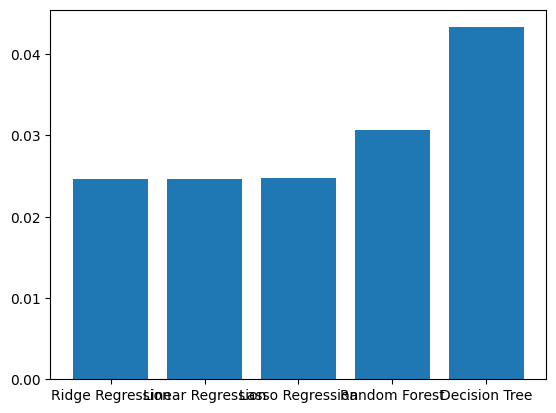

In [18]:
# plotting rmse comparison across models
plt.bar(metrics_summary['Model'], metrics_summary['Test RMSE'])
plt.show()

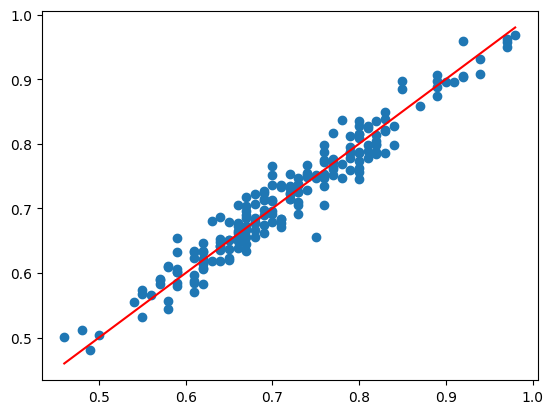

In [19]:
# plotting actual vs predicted values for best regression model
best_preds = predictions[best_model_name]['test']
plt.scatter(y_test, best_preds)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.show()

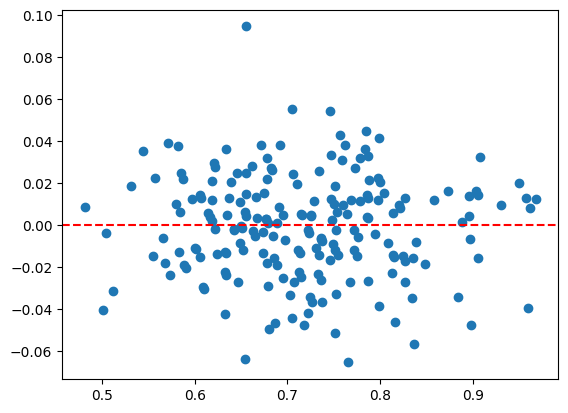

In [20]:
# plotting prediction residuals for best regression model
residuals = y_test - best_preds
plt.scatter(best_preds, residuals)
plt.axhline(0, color='red', linestyle='--')
plt.show()